# Figure 2 — INT deflections in HCP-YA: spatial structure and behaviour

The task-minus-rest INT deflection for one HCP-YA task (default: working memory), per subject and
parcel. Bottom row: partial correlations of each parcel's deflection with task accuracy, RT and
cognition (controlling age, sex, head motion and mean rest INT), plotted against the S-A axis and
tested against BrainSMASH spatial nulls.

In [1]:
import os
import warnings
warnings.simplefilter("ignore", UserWarning)
warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
import scipy as sp
import pandas as pd

import matplotlib.pyplot as plt

%matplotlib inline

from src import nulls
from src.notebook import control_tag, load_notebook_data, load_rest_controls
from src.timescales import INT_METHOD, rest_window_match_for, rest_window_token
from src.plotting import figure_scratch_dir, setup_notebook_style
from snaplab_tools.plotting.utils import get_snap_colors, save_panel
from src.timescales import (convert_data_dict, average_data_dict_converted,
                             compute_regional_corrs, compute_deflections,
                             create_ints_dataframe_custom_grouping)
from src.gams import apply_region_mask, build_nuisance
from snaplab_tools.plotting.plotting import plot_correlation

setup_notebook_style()

## Panel + analysis support

Helpers for this notebook, gathered so the cells below stay readable. Collapse it.

In [2]:
# ── Panel + analysis support ────────────────────────────────────────────────────────────────
def defl_stats(rest, task):
    """(mean, variability) across subjects for one rest/task pair, honouring the toggles.

    Variability is std(d) / mean|d| under 'cv' and std(d) under 'std'. The CV denominator
    is always the magnitude mean so the statistic stays finite and comparable whether or
    not DEFLECTION_ABS is set (see the note above).
    """
    d = compute_deflections(rest, task, absolute=DEFLECTION_ABS)
    mean_d = np.nanmean(d, axis=0)
    std_d  = np.nanstd(d, axis=0)
    if VARIABILITY_STAT == 'std':
        return mean_d, std_d
    return mean_d, std_d / np.nanmean(np.abs(compute_deflections(rest, task)), axis=0)


def _stack_mean(d, patterns):
    arrays = [d[k] for k in d if any(p in k for p in patterns) and d[k] is not None]
    return np.nanmean(np.stack(arrays, axis=0), axis=0) if arrays else None


def _to_full(vec_masked):
    """Re-expand a masked (valid-region) vector to the full 400-parcel grid (NaN at masked regions)."""
    full = np.full(n_regions_full, np.nan)
    full[~region_mask] = vec_masked
    return full


def _make_surrogates(vec_full, name):
    return nulls.generate_surrogates(
        vec_full, name=name, n_regions=n_regions_full, n_perms=N_PERMS, kind='geodesic',
        distance_matrix=distance_matrix, hemi=hemi_labels,
        cache_dir=surrogate_cache_dir)


def _panel_null(y_full, panel_slug):
    """Spatial-null test of corr(y-axis map, S-A axis) for one panel, honouring NULL_TARGET.

    Returns corr_with_null's dict (r, p_smash, n, null_lo, null_hi, null). The observed r is
    identical under both targets -- correlation is symmetric -- so only p_smash moves.
    """
    if NULL_TARGET == 'sa':
        return nulls.corr_with_null(y_full, sa_axis_full, surr_sa, method=CORR_METHOD)
    surr_y = _make_surrogates(y_full, f'{_YMAP_KEY}-{panel_slug}')
    return nulls.corr_with_null(sa_axis_full, y_full, surr_y, method=CORR_METHOD)


def _row_subjects(processor, dd, tasks):
    """Subject order of convert_data_dict's stacked rows, verified consistent across `tasks`.

    convert_data_dict stacks one row per scan in registry order and silently skips scans that
    are absent from `dd`, so the row -> subject mapping is only well defined when every
    constituent scan of an averaged group yields the same subject sequence. Checked, not assumed.
    """
    orders = [[s.subject_id for s in processor.scan_registry
               if s.task == t and str(s) in dd] for t in tasks]
    for o in orders[1:]:
        if o != orders[0]:
            raise ValueError('constituent scans disagree on subject order')
    return np.asarray(orders[0], dtype=str)


def _reindex(subs, wanted):
    pos = {s: i for i, s in enumerate(subs)}
    return np.array([pos[s] for s in wanted])


def _half_violin(ax, vals, pos, side, color, width=0.75, floor=None):
    """One half of a split violin at `pos`, with a median rule on the same side.

    `floor` clips the kernel density at a hard bound. |r| cannot be negative, so without it
    the KDE puts visible mass below zero and the violin reads as if the data went there.
    """
    vp = ax.violinplot(vals, positions=[pos], widths=width,
                       showextrema=False, showmedians=False)
    for body in vp['bodies']:
        verts = body.get_paths()[0].vertices
        verts[:, 0] = (np.clip(verts[:, 0], -np.inf, pos) if side == 'left'
                       else np.clip(verts[:, 0], pos, np.inf))
        if floor is not None:
            verts[:, 1] = np.clip(verts[:, 1], floor, None)
        body.set_facecolor(color)
        body.set_edgecolor('none')
        body.set_alpha(0.85)
    med = np.nanmedian(vals)
    x0, x1 = (pos - width / 2, pos) if side == 'left' else (pos, pos + width / 2)
    ax.plot([x0, x1], [med, med], color='0.15', lw=1.0, solid_capstyle='butt', zorder=3)
    return med


In [3]:
dataset = 'HCP-YA'
use_7t = False
use_resids = True

# The HCP-YA task analysed (its LR and RL runs averaged), set before the load because the length-matched rest depends on it.
condition_name = 'WM'   # 'WM', 'EMOTION', 'GAMBLING', 'LANGUAGE', 'RELATIONAL', 'SOCIAL'
REST_RUNS = ['rfMRIREST1LR', 'rfMRIREST1RL', 'rfMRIREST2LR', 'rfMRIREST2RL']

# Contrast settings: REST_LENGTH 'matched' (rest cut to the task's run length) or 'full', COMPARATOR 'rest' or
# 'restctrl' (matched controls cut from REST_SOURCE 'clean' or 'noFIX' rest), and FILTER None or
# 'bp-0.01-0.08hz', with any non-default adding a file tag.
REST_LENGTH = 'matched'
COMPARATOR  = 'rest'        # main figure
# COMPARATOR  = 'restctrl'  # supplementary figure
REST_SOURCE = 'noFIX'       # COMPARATOR = 'restctrl' only
FILTER      = None

if COMPARATOR not in ('rest', 'restctrl'):
    raise ValueError(f"COMPARATOR must be 'rest' or 'restctrl'; got {COMPARATOR!r}")
REST_MATCH = rest_window_match_for(dataset, f'tfMRI{condition_name}LR') if REST_LENGTH == 'matched' else None
_rest_token = f'_{rest_window_token(REST_MATCH)}' if REST_MATCH else ''
CONFIG_TAG = (_rest_token if COMPARATOR == 'rest'
              else control_tag(REST_SOURCE) + ('_nuis-clean-restlen' if REST_MATCH else '_nuis-clean-raw'))
DEFAULT_TAG = '_restlen-WM'    # the tag of this notebook's default configuration (restlen, condition WM)
print(f'file tag: {CONFIG_TAG!r}')

output_type = f'timescale_{INT_METHOD}' + (f'_{FILTER}' if FILTER else '')
notebook_data = load_notebook_data(dataset=dataset, use_7t=use_7t, output_type=output_type, use_resids=use_resids,
                                   rest_length=REST_LENGTH, rest_match=REST_MATCH)

file tag: '_restlen-WM'
Loading data for notebooks...
Initialized DataLoader for dataset: HCP-YA
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/HCP_1200
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       1206 subjects

	Initialized Timescales for dataset: HCP-YA
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
	Brain-gene panel 'gao': 2031/2429 symbols present in the expression matrix -> PCA input (400, 2031).
Loaded 15456 scans from scan_registry_HCP-YA.csv


Loading timescale_auc_zero_crossing_restlen-WM: 100%|██████████| 15456/15456 [00:00<00:00, 22141.16it/s]


  rest_length='matched' (restlen-WM): 3864 rest scans use length-matched windows


Loading timescale_auc_zero_crossing_resids: 100%|██████████| 15456/15456 [00:01<00:00, 8025.41it/s]

Number of subjects: 966


In [4]:
fig_dir = figure_scratch_dir(dataset)

In [5]:
# get key outputs for this notebook
timescales_processor = notebook_data['timescales_processor']
data_dict = notebook_data['data_dict']
data_dict_tsnr = notebook_data['data_dict_tsnr']
results_dir = notebook_data['results_dir']

df_neuro = notebook_data['supporting_data']['df_neuro']
yeo_systems = notebook_data['supporting_data']['yeo_systems']

print(data_dict.keys())
print(df_neuro.columns)

dict_keys(['sub-100206_task-rfMRIREST1LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-rfMRIREST1RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-rfMRIREST2LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-rfMRIREST2RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-tfMRIWMLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIWMRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIEMOTIONLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIEMOTIONRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIGAMBLINGLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIGAMBLINGRL_space-fsLR

In [6]:
n_regions = len(yeo_systems)
n_systems = len(np.unique(yeo_systems))

In [7]:
subject_ids = list(dict.fromkeys(scan.subject_id for scan in timescales_processor.scan_registry))
n_subs = len(subject_ids)
print(f'Number of subjects: {n_subs}')

Number of subjects: 966


In [8]:
timescales_processor.match_registry_to_behavior()
print(timescales_processor.df_behavior_matched.shape)

(966, 593)


In [9]:
df_behavior = timescales_processor.df_behavior_matched.copy()
# Summarised rather than displayed: committed notebooks must not carry subject-level behaviour rows (dataset data-use terms).
print(f'df_behavior: {df_behavior.shape[0]} subjects x {df_behavior.shape[1]} columns')
print(', '.join(map(str, df_behavior.columns)))

df_behavior: 966 subjects x 593 columns
Release, Acquisition, Gender, Age, 3T_Full_MR_Compl, T1_Count, T2_Count, 3T_RS-fMRI_Count, 3T_RS-fMRI_PctCompl, 3T_Full_Task_fMRI, 3T_tMRI_PctCompl, fMRI_WM_PctCompl, fMRI_Gamb_PctCompl, fMRI_Mot_PctCompl, fMRI_Lang_PctCompl, fMRI_Soc_PctCompl, fMRI_Rel_PctCompl, fMRI_Emo_PctCompl, 3T_dMRI_Compl, 3T_dMRI_PctCompl, dMRI_3T_ReconVrs, fMRI_3T_ReconVrs, 7T_Full_MR_Compl, 7T_RS-fMRI_Count, 7T_RS-fMRI_PctCompl, 7T_Full_Task_fMRI, 7T_tMRI_PctCompl, fMRI_Movie_Compl, fMRI_Movie_PctCompl, fMRI_Ret_Compl, fMRI_Ret_PctCompl, 7T_dMRI_Compl, 7T_dMRI_PctCompl, 7T_fMRI_Mov_Vrs, MEG_AnyData, MEG_FullProt_Compl, MEG_HeadModel_Avail, MEG_CortRibn_Avail, MEG_Anatomy_Avail, MEG_Anatomy_Compl, MEG_Noise_Avail, MEG_Noise_Compl, MEG_RS_Avail, MEG_RS_Compl, MEG_WM_Avail, MEG_WM_Compl, MEG_StoryMath_Avail, MEG_StoryMath_Compl, MEG_Motor_Avail, MEG_Motor_Compl, Non-TB_Compl, VisProc_Compl, DelDisc_Compl, SCPT_Compl, IWRD_Compl, PMAT_Compl, VSPLOT_Compl, EmoRecog_Compl, NE

## Data for figures

In [10]:
brain_map = 'SA_Axis'
condition = f'task-{condition_name}'

def _group(d):
    return average_data_dict_converted(convert_data_dict(d, timescales_processor.scan_registry, verbose=False),
                                       average_3t_rest=True, average_3t_task_pairs=True)

# The REST_LENGTH rest is always the covariate's rest, and the deflection's rest side is either it or, under 'restctrl', each run's matched control.
dropped = {}
if COMPARATOR == 'restctrl':
    data_dict, controls, dropped = load_rest_controls(timescales_processor, data_dict, [condition],
                                                      rest_source=REST_SOURCE, filter=FILTER)
data_dict_converted = _group(data_dict)
nuisance_rest_full = data_dict_converted['task-REST_3T']
rest_full = _group(controls)[condition] if COMPARATOR == 'restctrl' else nuisance_rest_full
data_dict_converted.keys()

dict_keys(['task-REST_3T', 'task-WM', 'task-EMOTION', 'task-GAMBLING', 'task-LANGUAGE', 'task-RELATIONAL', 'task-SOCIAL'])

## INT deflection variance and covariance

In [11]:
# ── Deflection definition and rest-INT control ────────────────────────────────
# Deflection = task minus rest (rest INT is controlled only in the behavioural correlations), with
# DEFLECTION_ABS choosing signed (False) or magnitude (True) and VARIABILITY_STAT 'cv' (std / mean|d|) or 'std'.
DEFLECTION_ABS   = True   # False (signed) | True (absolute)
VARIABILITY_STAT = 'std'    # 'cv' | 'std'
# APPLY_TSNR_MASK drops the lowest-TSNR_QUANTILE parcels of the task condition (fig2 shares no cache with
# fig3/fig4, so it may mask freely).
APPLY_TSNR_MASK  = False    # False (all parcels) | True (drop low-tSNR parcels)
TSNR_QUANTILE    = 0.1      # only used when APPLY_TSNR_MASK
# ─────────────────────────────────────────────────────────────────────────────

if VARIABILITY_STAT not in ('cv', 'std'):
    raise ValueError(f"VARIABILITY_STAT must be 'cv' or 'std'; got {VARIABILITY_STAT!r}")

# Neural data for rest and task
rest_data = rest_full                                     # (n_subjects, n_regions): the comparator
task_data = data_dict_converted[f'task-{condition_name}'] # (n_subjects, n_regions)

behavior_measures = [
    f'{condition_name}_Task_Acc',
    f'{condition_name}_Task_Median_RT',
    'CogTotalComp_Unadj',
]

# With the mask off, region_mask is all False rather than None, so every consumer below works unchanged.
df_tsnr = create_ints_dataframe_custom_grouping(data_dict_tsnr, average_3t_task_pairs=True)
tsnr_col = f'task-{condition_name}'
if APPLY_TSNR_MASK:
    region_mask = (df_tsnr[tsnr_col] < np.quantile(df_tsnr[tsnr_col], q=TSNR_QUANTILE)).values
else:
    region_mask = np.zeros(len(df_tsnr[tsnr_col]), dtype=bool)
print(f'tSNR mask: {"ON" if APPLY_TSNR_MASK else "OFF"} -- '
      f'{int((~region_mask).sum())} of {len(region_mask)} parcels retained')

# Apply mask — drops low-tSNR regions from data arrays and SA axis (a no-op when the mask is off)
sa_axis_masked = df_neuro[brain_map].values.copy()
rest_data, task_data, sa_axis_masked = apply_region_mask(
    region_mask, rest_data, task_data, sa_axis=sa_axis_masked)
# The covariate's rest (nuisance_rest), masked the same way; the comparator itself when the two agree.
nuisance_rest = rest_data if COMPARATOR == 'rest' else apply_region_mask(region_mask, nuisance_rest_full)[0]
yeo_systems_masked = np.asarray(yeo_systems)[~region_mask]


deflection_matrix = compute_deflections(rest_data, task_data, absolute=DEFLECTION_ABS)
mean_deflection, var_deflection = defl_stats(rest_data, task_data)

# The rest-INT covariate is each subject's mean rest INT across regions, which removes global INT differences
# without reshaping the regional map.
subj_mean_rest = np.nanmean(nuisance_rest, axis=1)   # (n_subjects,)

# Covariates come from build_nuisance (shared with fig3/fig4), with HCP's relative RMS motion (not FD) for
# rest and task as separate columns.
_motion_task = f'meanRelRMS_{condition_name}'
beh_covariates = build_nuisance(df_behavior, nuisance_rest, dataset, include_age=True,
                                fd_columns=['meanRelRMS_rest', _motion_task])
_COV_LAB = f'age, sex, motion (rest + {condition_name}), mean rest INT'

# Axis-label fragments driven by the toggles.
_D_LAB = 'INT Deflection'
_V_LAB = 'CV' if VARIABILITY_STAT == 'cv' else 'Std. Dev.'

print(f'deflection         : {"absolute" if DEFLECTION_ABS else "signed"}')
print(f'variability stat   : {VARIABILITY_STAT}')
print(f'deflection_matrix  : {deflection_matrix.shape}')
print(f'mean_deflection    : {mean_deflection.shape}')
print(f'subj_mean_rest     : {subj_mean_rest.shape}  (rest-INT covariate for the bottom row)')
print(f'covariates         : {beh_covariates.shape}  [{_COV_LAB}]')
print(f'                     complete rows: {(~np.isnan(beh_covariates).any(axis=1)).sum()}'
      f'/{beh_covariates.shape[0]}  (NaN rows are dropped per region by partial_pearsonr)')

tSNR mask: OFF -- 400 of 400 parcels retained
region_mask: excluding 0 regions, 400 remaining.
deflection         : absolute
variability stat   : std
deflection_matrix  : (966, 400)
mean_deflection    : (400,)
subj_mean_rest     : (966,)  (rest-INT covariate for the bottom row)
covariates         : (966, 5)  [age, sex, motion (rest + WM), mean rest INT]
                     complete rows: 966/966  (NaN rows are dropped per region by partial_pearsonr)


In [12]:
# ── Split-half reliability data ───────────────────────────────────────────────
# Does the top-row variability statistic replicate across the LR and RL phase-encoding runs?
_data_raw = convert_data_dict(data_dict, timescales_processor.scan_registry, verbose=False)
# The comparator's runs per phase-encoding direction: the LR / RL rest runs, or the control of each task run.
_rest_raw = convert_data_dict(controls if COMPARATOR == 'restctrl' else data_dict,
                             timescales_processor.scan_registry, verbose=False)
_split = ({'LR': [f'tfMRI{condition_name}LR'], 'RL': [f'tfMRI{condition_name}RL']}
          if COMPARATOR == 'restctrl'
          else {'LR': ['rfMRIREST1LR', 'rfMRIREST2LR'], 'RL': ['rfMRIREST1RL', 'rfMRIREST2RL']})

_rest_lr = _stack_mean(_rest_raw, _split['LR'])
_rest_rl = _stack_mean(_rest_raw, _split['RL'])
_task_lr = _stack_mean(_data_raw, [f'tfMRI{condition_name}LR'])
_task_rl = _stack_mean(_data_raw, [f'tfMRI{condition_name}RL'])

_rest_lr_m = _rest_lr[:, ~region_mask]
_rest_rl_m = _rest_rl[:, ~region_mask]
_task_lr_m = _task_lr[:, ~region_mask]
_task_rl_m = _task_rl[:, ~region_mask]

_, var_defl_lr = defl_stats(_rest_lr_m, _task_lr_m)
_, var_defl_rl = defl_stats(_rest_rl_m, _task_rl_m)

print(f'Split-half r ({_V_LAB}): {float(sp.stats.pearsonr(var_defl_lr, var_defl_rl)[0]):.3f}')

Split-half r (Std. Dev.): 0.972


In [13]:
# ── Spatial nulls for the S-A-axis correlations ───────────────────────────────
# Each panel tests corr(map, S-A axis) against cached BrainSMASH surrogates of the map NULL_TARGET names: 'sa'
# (the S-A axis, the paper's design) or 'ymap' (each panel's own map, ~4 min per panel on first run, outputs suffixed).
NULL_TARGET    = 'sa'           # 'sa' | 'ymap'
SHOW_TOP_ROW   = True           # False: draw only the bottom row (behaviour panels)
CORR_METHOD    = 'pearson'

N_PERMS        = 10000
n_regions_full = len(region_mask)   # 400 (pre-mask); masked maps are re-expanded to this length

if NULL_TARGET not in ('sa', 'ymap'):
    raise ValueError(f"NULL_TARGET must be 'sa' or 'ymap', got {NULL_TARGET!r}")

distance_matrix, hemi_labels = nulls.load_distance_matrix(n_regions_full, kind='geodesic')
surrogate_cache_dir = nulls.surrogate_cache_dir(timescales_processor, dataset)

sa_axis_full = df_neuro[brain_map].values   # dense S-A axis over all 400 parcels

# S-A surrogates: only needed under NULL_TARGET='sa' (one set, reused by every panel).
surr_sa = _make_surrogates(sa_axis_full, 'SA_Axis') if NULL_TARGET == 'sa' else None

# The per-panel surrogate cache key encodes everything that changes the maps (condition, deflection definition, variability statistic, configuration tag).
_YMAP_KEY = (f'fig2-{condition_name}-defl{"abs" if DEFLECTION_ABS else "sgn"}'
             f'-{VARIABILITY_STAT}-v2' + ('' if CONFIG_TAG == DEFAULT_TAG else CONFIG_TAG))

print(f'null_target={NULL_TARGET} | n_perms={N_PERMS}')
if NULL_TARGET == 'sa':
    print(f'  S-A surrogates {surr_sa.shape} (n_perms x n_regions), reused by every panel')
else:
    print(f'  per-panel surrogates of each y-axis map; cache key prefix: {_YMAP_KEY}')
    print('  first run generates 5 surrogate sets (~4 min each), cached on disk thereafter')

null_target=sa | n_perms=10000
  S-A surrogates (10000, 400) (n_perms x n_regions), reused by every panel


## Figure 2

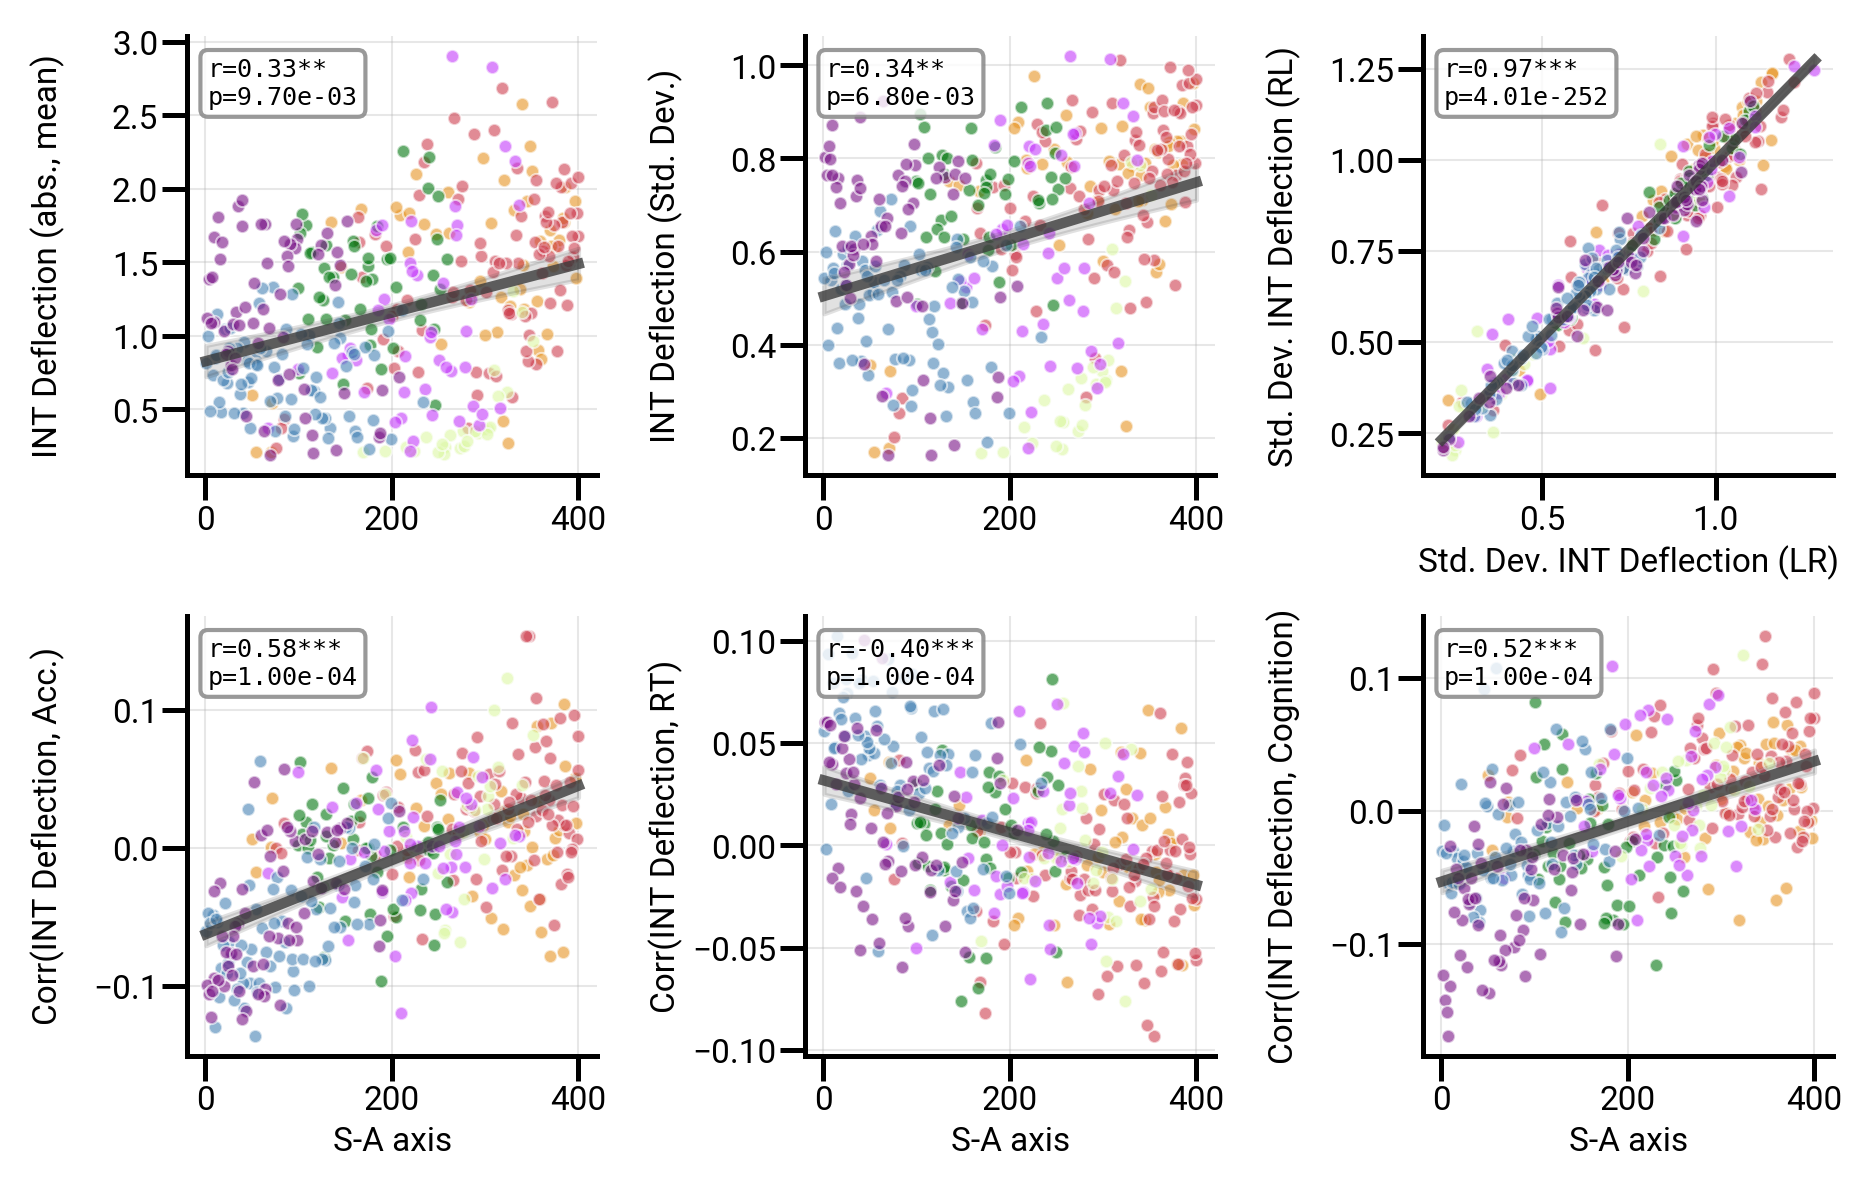

                          panel         r  p_smash   n
    INT Deflection (abs., mean)  0.332491   0.0097 400
     INT Deflection (Std. Dev.)  0.342336   0.0068 400
     Corr(INT Deflection, Acc.)  0.584324   0.0000 400
       Corr(INT Deflection, RT) -0.395110   0.0000 400
Corr(INT Deflection, Cognition)  0.518927   0.0000 400


In [14]:
# SHOW_TOP_ROW = False draws only the bottom row (file suffix '_bottomrow'), but every statistic and the CSV are computed either way.
fig, axes = plt.subplots(nrows=2 if SHOW_TOP_ROW else 1, ncols=len(behavior_measures),
                         sharex=False, sharey=False,
                         figsize=(len(behavior_measures)*2.1, 4 if SHOW_TOP_ROW else 2), dpi=300)
top_axes, bottom_axes = (axes[0], axes[1]) if SHOW_TOP_ROW else (None, axes)
_row_suffix = '' if SHOW_TOP_ROW else '_bottomrow'

sa_null_rows = []   # per-panel r / p_smash for the S-A-axis correlations -> saved to results_dir

# Spatially tested panels print the BrainSMASH p, never the parametric p that ignores spatial autocorrelation
# (the split-half panel is the one exception).
# _panel_null surrogates the map NULL_TARGET names, caching each panel's map under its panel_slug.

# Top row: the deflection's mean and variability against the S-A axis, without rest control or behaviour.
variance_panels = [
    (mean_deflection, f'{_D_LAB} (abs., mean)',   'mean-defl'),
    (var_deflection,  f'{_D_LAB} ({_V_LAB})', f'{VARIABILITY_STAT}-defl'),
]
for i, (stat_data, stat_label, panel_slug) in enumerate(variance_panels):
    d = _panel_null(_to_full(stat_data), panel_slug)
    sa_null_rows.append({'panel': stat_label, 'r': d['r'], 'p_smash': d['p_smash'], 'n': d['n'],
                         'null_target': NULL_TARGET})
    if SHOW_TOP_ROW:
        plot_correlation(sa_axis_masked, stat_data, top_axes[i],
                         data_group=yeo_systems_masked, show_stats=True, fontsize=8, method=CORR_METHOD,
                         y_label=stat_label, x_label=' ', size=10, cbar_label='Yeo Systems',
                         show_colorbar=False, data_group_cmap='yeo7',
                         auto_polynomial=False, custom_pvalue=d['p_smash'])

# Top row panel 3: split-half reliability (LR vs RL)
if SHOW_TOP_ROW:
    plot_correlation(var_defl_lr, var_defl_rl, top_axes[2],
                     data_group=yeo_systems_masked, show_stats=True, fontsize=8, method=CORR_METHOD,
                     y_label=f'{_V_LAB} {_D_LAB} (RL)', x_label=f'{_V_LAB} {_D_LAB} (LR)',
                     size=10, cbar_label='Yeo Systems', show_colorbar=False,
                     data_group_cmap='yeo7', auto_polynomial=False)
# axes[0, 2].set_title('Phase-encoding consistency', fontsize=8, pad=3)

# Bottom row: partial correlations of each parcel's deflection with behaviour, controlling beh_covariates.
_BEHAVIOR_SLUGS = {'Acc.': 'corr-acc', 'RT': 'corr-rt', 'Cognition': 'corr-cog'}
for i, behavior_measure in enumerate(behavior_measures):
    behavior_data = df_behavior[behavior_measure].values.astype(float)
    rest_correlations, task_correlations, deflection_correlations = compute_regional_corrs(
        rest_data, task_data, behavior_data,
        covariate=beh_covariates, absolute=DEFLECTION_ABS)

    if 'Acc' in behavior_measure:
        y_sublabel = 'Acc.'
    elif 'RT' in behavior_measure:
        y_sublabel = 'RT'
    else:
        y_sublabel = 'Cognition'

    file_label = f'Corr({_D_LAB}, {y_sublabel})'
    d = _panel_null(_to_full(deflection_correlations), _BEHAVIOR_SLUGS[y_sublabel])
    sa_null_rows.append({'panel': file_label, 'r': d['r'], 'p_smash': d['p_smash'], 'n': d['n'],
                         'null_target': NULL_TARGET, 'covariates': _COV_LAB})
    plot_correlation(sa_axis_masked, deflection_correlations, bottom_axes[i],
                     data_group=yeo_systems_masked, show_stats=True, fontsize=8, method=CORR_METHOD,
                     y_label=file_label, x_label='S-A axis', size=10, cbar_label='Yeo Systems',
                     show_colorbar=False, data_group_cmap='yeo7',
                     auto_polynomial=False, custom_pvalue=max(d['p_smash'], 1 / N_PERMS))

for ax in axes.flat:
    ax.yaxis.set_label_coords(-0.3, 0.5)
    ax.tick_params(axis='y', which='major', pad=1)
    ax.tick_params(axis='x', which='major', pad=1)
    ax.xaxis.labelpad = 2

fig.tight_layout()
# Any configuration other than the primary one (sa null, signed deflection, CV) gets a suffix, so it never
# overwrites the committed figure and CSV.
_is_primary  = (NULL_TARGET == 'sa' and not DEFLECTION_ABS and VARIABILITY_STAT == 'cv')
_null_suffix = ''
if not _is_primary:
    _null_suffix = f'_{NULL_TARGET}'
    if DEFLECTION_ABS:
        _null_suffix += '-abs'
    if VARIABILITY_STAT != 'cv':
        _null_suffix += f'-{VARIABILITY_STAT}'
save_panel(fig, fig_dir, f'corr_ints_sa{_null_suffix}{_row_suffix}{CONFIG_TAG}', transparent=True)
plt.show()

# S-A-axis spatial-null statistics
pd.DataFrame(sa_null_rows).to_csv(
    os.path.join(results_dir, f'corr_ints_sa_nulls{_null_suffix}{CONFIG_TAG}.csv'), index=False)
print(pd.DataFrame(sa_null_rows)[['panel', 'r', 'p_smash', 'n']].to_string(index=False))

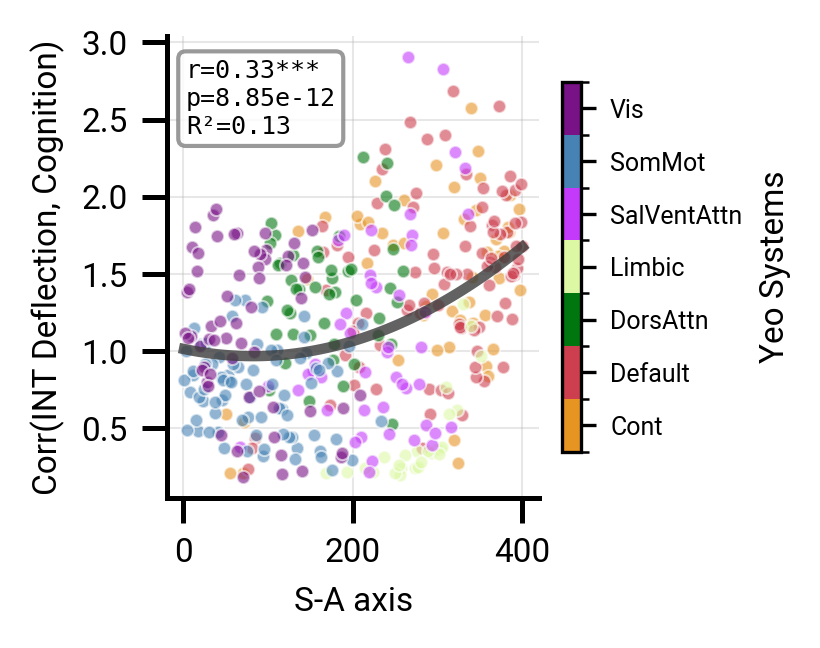

In [15]:
# another one just for the colorbar
fig, axes = plt.subplots(nrows=1, ncols=1,
                         sharex=True, sharey=False,
                         figsize=(2, 2), dpi=300)

plot_correlation(sa_axis_masked, mean_deflection, axes, 
                data_group=yeo_systems_masked, show_stats=True, fontsize=8,
                y_label=file_label, x_label='S-A axis', size=10, cbar_label='Yeo Systems', show_colorbar=True, data_group_cmap='yeo7',
                auto_polynomial=True, models_to_test=[1, 2], model_selection_metric='variance_explained')

save_panel(fig, fig_dir, 'corr_ints_sa_colorbar' + ('' if CONFIG_TAG == DEFAULT_TAG else CONFIG_TAG),
           transparent=True)
plt.show()

## Supplementary: does task regression change the behavioural correlations?

In [16]:
# ── Supp: behavioural correlations with vs without task regression ────────────
# Recompute the behavioural correlations without task regression, on the same subjects, regions and
# covariates, comparing |r| (ABS_R, the default) or signed r.
ABS_R = True
# ─────────────────────────────────────────────────────────────────────────────

if COMPARATOR == 'restctrl':
    print("WARNING: the without-regression side compares a raw task INT with a control that had the task's "
          "design projected out")

# Reload without task regression, reading the rest side exactly as the config cell does.
notebook_data_noreg = load_notebook_data(
    dataset=dataset, use_7t=use_7t, output_type=output_type, use_resids=False,
    rest_length=REST_LENGTH, rest_match=REST_MATCH)
proc_noreg      = notebook_data_noreg['timescales_processor']
data_dict_noreg = notebook_data_noreg['data_dict']
proc_noreg.match_registry_to_behavior()
noreg_dropped = {}
if COMPARATOR == 'restctrl':
    data_dict_noreg, controls_noreg, noreg_dropped = load_rest_controls(
        proc_noreg, data_dict_noreg, [condition], rest_source=REST_SOURCE, filter=FILTER)


def _group_noreg(d):
    return average_data_dict_converted(convert_data_dict(d, proc_noreg.scan_registry, verbose=False),
                                       average_3t_rest=True, average_3t_task_pairs=True)


conv_noreg = _group_noreg(data_dict_noreg)
_rest_noreg_full = (_group_noreg(controls_noreg)[condition] if COMPARATOR == 'restctrl'
                    else conv_noreg['task-REST_3T'])
# Same region_mask as the main figure, so both sides describe the same parcels.
rest_noreg, task_noreg, _ = apply_region_mask(
    region_mask, _rest_noreg_full, conv_noreg[f'task-{condition_name}'])

# The two runs can keep different subjects (a failed task GLM drops a subject from the regressed run only), so compare on their intersection.
_subs_with    = _row_subjects(timescales_processor, data_dict, REST_RUNS)
_subs_without = _row_subjects(proc_noreg, data_dict_noreg, REST_RUNS)
_common = np.asarray([s for s in _subs_with if s in set(_subs_without)])


_iw, _io = _reindex(_subs_with, _common), _reindex(_subs_without, _common)
print(f'subjects: with={len(_subs_with)}  without={len(_subs_without)}  common={len(_common)}')

# The covariate's rest is the main figure's nuisance_rest on the common subjects, for both sides: rest is not
# task-regressed, so it is the same in both runs (asserted below for the comparator).
supp_sides = {
    'With regression':    (rest_data[_iw],  task_data[_iw],  df_behavior.loc[_common], nuisance_rest[_iw]),
    'Without regression': (rest_noreg[_io], task_noreg[_io],
                                proc_noreg.df_behavior_matched.loc[_common],
                           nuisance_rest[_iw] if COMPARATOR == 'restctrl' else rest_noreg[_io]),
}

supp_corrs = {}
for _lab, (_rest, _task, _beh, _nuis) in supp_sides.items():
    # Same covariate set as the main figure, rebuilt per side so the comparison stays valid
    # even if the two runs ever end up with different subject sets.
    _cov = build_nuisance(_beh, _nuis, dataset, include_age=True,
                          fd_columns=['meanRelRMS_rest', _motion_task])
    supp_corrs[_lab] = {
        bm: compute_regional_corrs(_rest, _task, _beh[bm].values.astype(float),
                                   covariate=_cov, absolute=DEFLECTION_ABS)[2]
        for bm in behavior_measures
    }

# Rest is identical in both runs because task regression never touches rest scans, so a non-zero difference
# here would mean the runs are not comparable.
_rest_delta = np.nanmax(np.abs(supp_sides['With regression'][0]
                               - supp_sides['Without regression'][0]))
print(f'rest INT identical across runs: max|diff| = {_rest_delta:.3e}  (expected exactly 0)')

Loading data for notebooks...
Initialized DataLoader for dataset: HCP-YA
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/HCP_1200
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       1206 subjects

	Initialized Timescales for dataset: HCP-YA
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
	Brain-gene panel 'gao': 2031/2429 symbols present in the expression matrix -> PCA input (400, 2031).
Loaded 15456 scans from scan_registry_HCP-YA.csv


Loading timescale_auc_zero_crossing_restlen-WM: 100%|██████████| 15456/15456 [00:00<00:00, 21646.55it/s]


  rest_length='matched' (restlen-WM): 3864 rest scans use length-matched windows
Number of subjects: 966
region_mask: excluding 0 regions, 400 remaining.
subjects: with=966  without=966  common=966
rest INT identical across runs: max|diff| = 0.000e+00  (expected exactly 0)


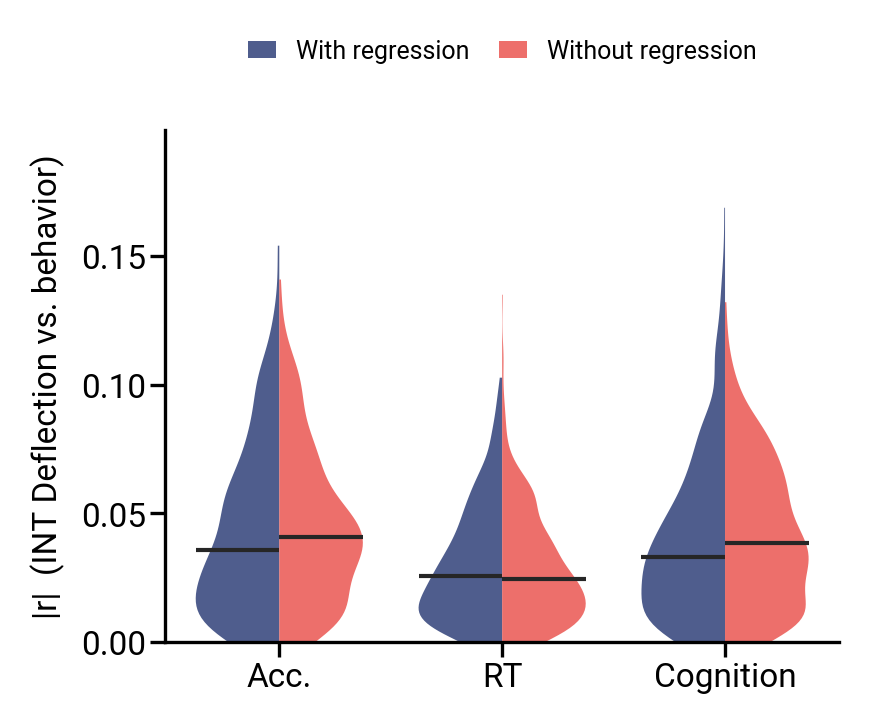

 behavior          condition   median     mean  n_regions
     Acc.    With regression 0.035873 0.042967        400
     Acc. Without regression 0.040906 0.045009        400
       RT    With regression 0.025664 0.030586        400
       RT Without regression 0.024536 0.028844        400
Cognition    With regression 0.033269 0.040080        400
Cognition Without regression 0.038694 0.041959        400


In [17]:
# ── Supp figure: |r| distributions, with vs without task regression ───────────
# Split violins of |r| across regions, task-regressed (left) against not (right), described by medians only
# because parcels are not independent observations.
_SHORT = {behavior_measures[0]: 'Acc.', behavior_measures[1]: 'RT',
          behavior_measures[2]: 'Cognition'}
_snap  = get_snap_colors(normalize=True)
_COL   = {'With regression':    _snap['starry_night_blue'],
          'Without regression': _snap['raspberry_blush']}   # CVD dE 21.5 (comfortable)


fig, ax = plt.subplots(figsize=(3, 2.5), dpi=300)
supp_rows, _vmax = [], 0.0
for i, bm in enumerate(behavior_measures):
    for _side, _lab in (('left', 'With regression'), ('right', 'Without regression')):
        v = supp_corrs[_lab][bm]
        v = np.abs(v) if ABS_R else v
        v = v[~np.isnan(v)]
        _vmax = max(_vmax, v.max())
        _med = _half_violin(ax, v, i, _side, _COL[_lab], floor=0.0 if ABS_R else None)
        supp_rows.append({'behavior': _SHORT[bm], 'condition': _lab,
                          'median': _med, 'mean': v.mean(),
                          'q25': np.percentile(v, 25), 'q75': np.percentile(v, 75),
                          'n_regions': v.size, 'n_subjects': len(_common),
                          'abs_r': ABS_R, 'deflection_abs': DEFLECTION_ABS})

# Headroom so the deltas sit above the widest violin rather than on top of it.
ax.set_ylim(0 if ABS_R else None, _vmax * 1.18)
# for i in range(len(behavior_measures)):
#     _d = supp_rows[2 * i]['median'] - supp_rows[2 * i + 1]['median']
#     ax.annotate(f'$\\Delta$={_d:+.4f}', xy=(i, _vmax * 1.10), ha='center', va='bottom',
#                 fontsize=6, color='0.35')

ax.set_xticks(range(len(behavior_measures)))
ax.set_xticklabels([_SHORT[b] for b in behavior_measures])
ax.set_ylabel(f'{"|r|" if ABS_R else "r"}  ({_D_LAB} vs. behavior)')
ax.tick_params(axis='both', which='major', pad=1)
_handles = [plt.Rectangle((0, 0), 1, 1, fc=_COL[k], alpha=0.85, ec='none') for k in _COL]
ax.legend(_handles, list(_COL), fontsize=6, frameon=False, loc='upper center',
          bbox_to_anchor=(0.5, 1.22), ncol=2, handlelength=1.1, columnspacing=1.2)

fig.tight_layout()
_supp_suffix = ('-abs' if DEFLECTION_ABS else '') + ('' if ABS_R else '-signedr')
save_panel(fig, fig_dir, f'corr_ints_behavior_taskreg{_supp_suffix}{CONFIG_TAG}')
plt.show()

pd.DataFrame(supp_rows).to_csv(
    os.path.join(results_dir, f'corr_ints_behavior_taskreg{_supp_suffix}{CONFIG_TAG}.csv'), index=False)
print(pd.DataFrame(supp_rows)[['behavior', 'condition', 'median', 'mean', 'n_regions']]
      .to_string(index=False))